# **Практическая работа №5. Работа с растровыми данными в Rasterio**

---

**Данные для обработки:**

- Одноканальное изображение (ЦМР): https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif
- Мультиспектральное изображение (Landsat): https://github.com/opengeos/datasets/releases/download/raster/cog.tif

### **Задание 1. Чтение и исследование растровых данных**



1. Откройте одноканальное изображение ЦМР с использованием `rasterio`.


2. Извлеките и выведите метаданные растра, включая СК, разрешение, границы, количество каналов и типы данных.


3. Отобразите ширину и высоту растра, а также типы данных пикселей, чтобы понять размеры сетки и структуру данных.

---



### **Задание 2. Визуализация и манипулирование растровыми каналами**



1. Визуализируйте одноканальное изображение ЦМР с использованием пользовательской цветовой карты (например, cmap='terrain').


2. Откройте мультиспектральное изображение и визуализируйте первый канал с использованием подходящей цветовой карты.


3. Объедините несколько каналов из мультиспектрального изображения (например, Красный, Зеленый и Синий) и совместите их в один массив для создания RGB-композитного изображения.

>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

---



### **Задание 3. Обрезка растра с использованием индексации массива**



1. Откройте мультиспектральное изображение и обрежьте его с использованием спискового среза (указав диапазоны строк и столбцов).


2. Визуализируйте обрезанную часть изображения с использованием matplotlib, чтобы убедиться в корректном результате.


>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

3. Сохраните обрезанное подмножество растра в новый файл с именем `clipped_multispectral.tif`.

---



### **Задание 4. Вычисление NDWI (калькуляция каналов)**



1. Откройте мультиспектральное изображение и извлеките каналы Green (Зеленый) и Ближний инфракрасный (NIR).


2. Вычислите Нормализованный разностный водный индекс ([NDWI](https://en.wikipedia.org/wiki/Normalized_difference_water_index)) по формуле:

    NDWI = (Green - NIR) / (Green + NIR)

3. Визуализируйте результат NDWI с использованием цветовой карты, подходящей для воды (например, cmap='Blues'), чтобы выделить водные объекты.




4. Сохраните полученное изображение NDWI как новый растровый файл с именем ndwi.tif.

---



### **Задание 5. Перепроецирование растровых данных**



1. Перепроецируйте одноканальный растр ЦМР из его исходной СК в EPSG:4326 (WGS 84) с использованием функции `rasterio.warp.reproject`.


2. Сохраните перепроецированный растр в новый файл GeoTIFF с именем `reprojected_dem.tif`.


3. Визуализируйте как исходный, так и перепроецированный наборы данных ЦМР, чтобы сравнить, как перепроецирование влияет на пространственное покрытие и разрешение.

---

In [1]:
from urllib.request import urlretrieve

import numpy as np
import rasterio
from rasterio.plot import plotting_extent
from rasterio.warp import Resampling, calculate_default_transform, reproject
from rasterio.windows import Window

base_url = "https://github.com/opengeos/datasets/releases/download/raster/"
for name in ["dem_90m.tif", "cog.tif"]:
    urlretrieve(base_url + name, name)


def normalize(band):
    band = np.ma.masked_invalid(band.astype(np.float32))
    band_min = band.min()
    band_max = band.max()
    return (band - band_min) / (band_max - band_min)


def make_rgb(bands):
    red = normalize(bands[0])
    green = normalize(bands[1])
    blue = normalize(bands[2])
    return np.dstack((red.filled(0), green.filled(0), blue.filled(0)))


with rasterio.open("cog.tif") as src:
    multispectral = src.read(masked=True)
    landsat_profile = src.profile.copy()
    landsat_extent = plotting_extent(src)

    row_start, row_stop = 35, 169
    col_start, col_stop = 72, 255
    clipped = multispectral[:, row_start:row_stop, col_start:col_stop]
    window = Window(col_start, row_start, clipped.shape[2], clipped.shape[1])
    clipped_profile = landsat_profile.copy()
    clipped_profile.update(width=clipped.shape[2], height=clipped.shape[1],
                           transform=src.window_transform(window))

with rasterio.open("clipped_multispectral.tif", "w", **clipped_profile) as dst:
    dst.write(clipped)

first_band = normalize(multispectral[0])
rgb = make_rgb(multispectral)
rgb_clipped = make_rgb(clipped)

green = np.ma.masked_invalid(multispectral[1].astype(float))
nir = np.ma.masked_invalid(multispectral[3].astype(float))
ndwi = np.ma.divide(green - nir, green + nir)

ndwi_profile = landsat_profile.copy()
ndwi_profile.update(count=1, dtype="float32", nodata=np.nan, interleave="band")
with rasterio.open("ndwi.tif", "w", **ndwi_profile) as dst:
    dst.write(ndwi.filled(np.nan).astype(np.float32), 1)
    dst.set_band_description(1, "NDWI")

dst_crs = "EPSG:4326"

with rasterio.open("dem_90m.tif") as src:
    dem = src.read(1, masked=True)
    dem_meta = src.meta
    dem_dtypes = src.dtypes
    dem_res = src.res
    dem_bounds = src.bounds
    dem_extent = plotting_extent(src)

    transform, width, height = calculate_default_transform(
        src.crs, dst_crs, src.width, src.height, *src.bounds
    )
    dem_profile = src.profile.copy()
    dem_profile.update(crs=dst_crs, transform=transform, width=width, height=height,
                       dtype="float32", nodata=np.nan, predictor=3)

    with rasterio.open("reprojected_dem.tif", "w", **dem_profile) as dst:
        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs=dst_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

with rasterio.open("reprojected_dem.tif") as src:
    reprojected_dem = src.read(1, masked=True)
    reprojected_res = src.res
    reprojected_bounds = src.bounds
    reprojected_extent = plotting_extent(src)


Исходная ЦМР
Формат: GTiff
СК: EPSG:3857
Размер: 4269 × 3113 пикселей
Разрешение: 90.000 × 89.996 м
Границы (запад, юг, восток, север): (-13442488.3428, 4388214.6777, -13058278.3428, 4668371.5775)
Каналов: 1. Типы данных: ('int16',)

Размер фрагмента: 183 × 134 пикселей
NDWI: от -0.622 до 0.477

ЦМР после перепроецирования
СК: EPSG:4326
Размер: 4575 × 2642 пикселей
Разрешение: 0.00075433 × 0.00075433°
Границы (запад, юг, восток, север): (-120.755927, 36.633991, -117.30488, 38.626923)

Сохранены clipped_multispectral.tif, ndwi.tif и reprojected_dem.tif.


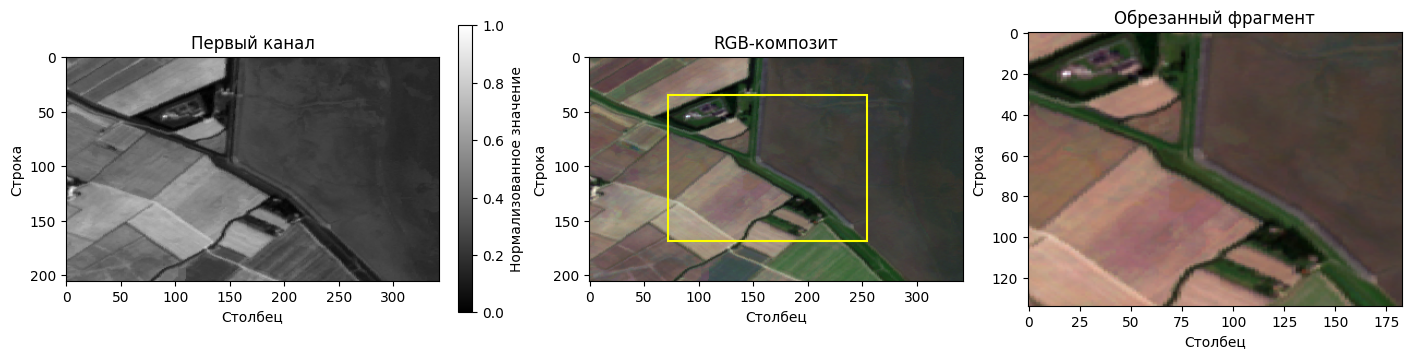

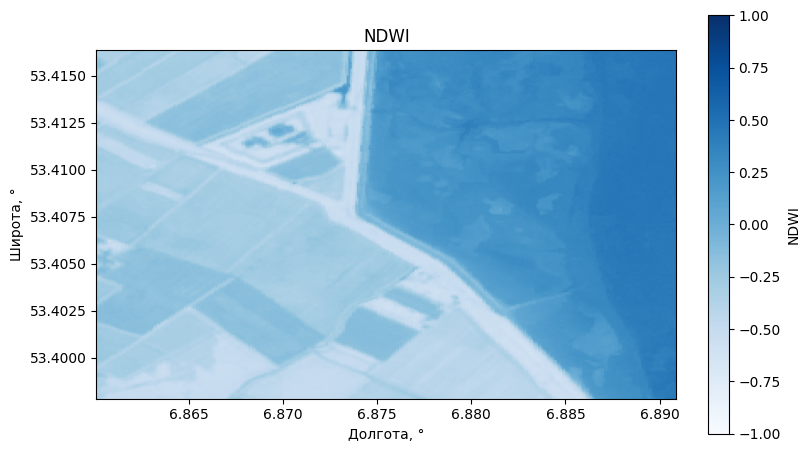

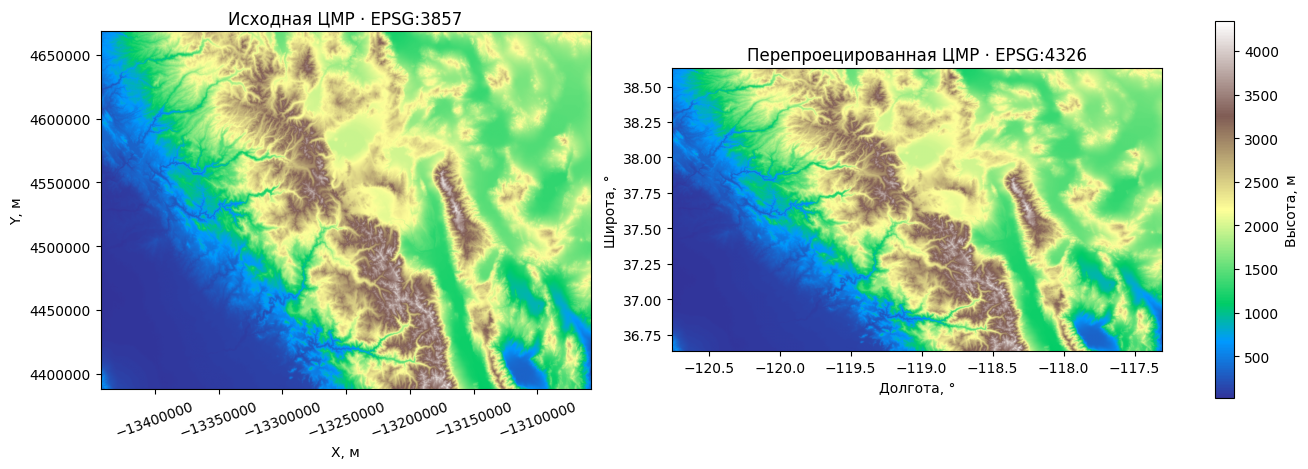

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

print("Исходная ЦМР")
print(f"Формат: {dem_meta['driver']}")
print(f"СК: {dem_meta['crs']}")
print(f"Размер: {dem_meta['width']} × {dem_meta['height']} пикселей")
print(f"Разрешение: {dem_res[0]:.3f} × {dem_res[1]:.3f} м")
print(f"Границы (запад, юг, восток, север): {tuple(dem_bounds)}")
print(f"Каналов: {dem_meta['count']}. Типы данных: {dem_dtypes}")
print()
print(f"Размер фрагмента: {clipped.shape[2]} × {clipped.shape[1]} пикселей")
print(f"NDWI: от {ndwi.min():.3f} до {ndwi.max():.3f}")
print()
print("ЦМР после перепроецирования")
print(f"СК: {dst_crs}")
print(f"Размер: {width} × {height} пикселей")
print(f"Разрешение: {reprojected_res[0]:.8f} × {reprojected_res[1]:.8f}°")
print(f"Границы (запад, юг, восток, север): {tuple(round(x, 6) for x in reprojected_bounds)}")
print()
print("Сохранены clipped_multispectral.tif, ndwi.tif и reprojected_dem.tif.")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
band_plot = axes[0].imshow(first_band, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Первый канал")
fig.colorbar(band_plot, ax=axes[0], shrink=0.65, label="Нормализованное значение")

axes[1].imshow(rgb)
axes[1].set_title("RGB-композит")
axes[1].add_patch(Rectangle((col_start - 0.5, row_start - 0.5),
                            clipped.shape[2], clipped.shape[1],
                            fill=False, edgecolor="yellow", linewidth=1.5))
axes[2].imshow(rgb_clipped)
axes[2].set_title("Обрезанный фрагмент")
for ax in axes:
    ax.set_xlabel("Столбец")
    ax.set_ylabel("Строка")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ndwi_plot = ax.imshow(ndwi, cmap="Blues", vmin=-1, vmax=1, extent=landsat_extent)
ax.set_title("NDWI")
ax.set_xlabel("Долгота, °")
ax.set_ylabel("Широта, °")
ax.ticklabel_format(useOffset=False)
fig.colorbar(ndwi_plot, ax=ax, label="NDWI")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
vmin, vmax = dem.min(), dem.max()
axes[0].imshow(dem, cmap="terrain", extent=dem_extent, vmin=vmin, vmax=vmax)
axes[0].set_title("Исходная ЦМР · EPSG:3857")
axes[0].set_xlabel("X, м")
axes[0].set_ylabel("Y, м")
axes[0].ticklabel_format(style="plain", useOffset=False)
axes[0].tick_params(axis="x", labelrotation=20)

dem_plot = axes[1].imshow(reprojected_dem, cmap="terrain", extent=reprojected_extent,
                          vmin=vmin, vmax=vmax)
axes[1].set_title("Перепроецированная ЦМР · EPSG:4326")
axes[1].set_xlabel("Долгота, °")
axes[1].set_ylabel("Широта, °")
axes[1].ticklabel_format(useOffset=False)
fig.colorbar(dem_plot, ax=axes, shrink=0.8, label="Высота, м")
plt.show()
